# 2D Object Detection — COCO → KITTI Deep-Dive (Track A)

**3 detector families × 2 datasets**, all scored with the same pycocotools pipeline.

| Family | Model | Checkpoint |
|---|---|---|
| One-stage CNN (YOLO) | YOLO26-L (NMS-free one-to-one head; also run with its one-to-many head + NMS) | `weights/yolo26l.pt` |
| Query-based transformer (DETR) | RT-DETR-L | `weights/rtdetr-l.pt` |
| Two-stage CNN (R-CNN) | Faster R-CNN ResNet50-FPN v2 | torchvision `COCO_V1` |

Datasets: **COCO val2017** (5,000 images, in-domain) and **KITTI 2D object** (1,000-image seeded subset of `training/`, zero-shot, no retraining).

### Requirement checklist (Track A)

| Requirement | Where in this notebook |
|---|---|
| ≥3 model configs, ≥2 families | §1 (3 families, 4 configs) |
| ≥2 datasets + taxonomy mapping | §2 |
| mAP, AP50/75, AP S/M/L, per-class AP, AR, latency/FPS, GPU memory | §4, §5, §8 |
| Reproducibility: checkpoint, split, resolution, thresholds, hardware, framework, command | §3 |
| Evidence experiments were run | §3 (logs), §4 (live inference), all numbers loaded from `results/*.json` |
| Analysis 1 — cross-dataset generalization (classes, scales) | §6, §7 |
| Analysis 2 — speed–accuracy tradeoff | §8 |
| Analysis 3 — architecture comparison (NMS vs NMS-free, queries vs anchors) | §9 |
| Failure analysis | §10 |
| Conclusions, references | §11, §12 |

In [1]:
import os, json, copy, contextlib, io, subprocess
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from IPython.display import Markdown, display, Image

pd.set_option("display.precision", 1)
R = Path("results")
COCO_ANN = "data/coco/annotations/instances_val2017.json"
KITTI_ANN, KITTI_IMG = "data/kitti/kitti_coco.json", "data/kitti/training/image_2"
MODELS = [("YOLO26-L", "yolo26l"), ("YOLO26-L +NMS", "yolo26l-nms"),
          ("RT-DETR-L", "rtdetr-l"), ("Faster R-CNN v2", "frcnn-r50-fpn-v2")]
COLORS = dict(zip([m for m, _ in MODELS], ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]))
STATS = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large"]

def load(tag):
    p = R / f"{tag}.json"
    return json.loads(p.read_text()) if p.exists() else None

res = {(name, ds): load(f"{tag}_{ds}") for name, tag in MODELS for ds in ("coco", "kitti")}
assert all(res.values()), "run eval.py for all models first"

def quiet(fn, *a, **k):
    with contextlib.redirect_stdout(io.StringIO()):
        return fn(*a, **k)

def run_eval(gt, pred_file, cat_ids=None):
    E = COCOeval(gt, quiet(gt.loadRes, pred_file), "bbox")
    if cat_ids: E.params.catIds = cat_ids
    quiet(E.evaluate); quiet(E.accumulate); quiet(E.summarize)
    return E

def style(ax, ygrid=True):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.tick_params(colors="#6b6a63"); ax.set_axisbelow(True)
    if ygrid: ax.grid(axis="y", color="#e4e3dd", lw=0.8)

coco_gt, kitti_gt = quiet(COCO, COCO_ANN), quiet(COCO, KITTI_ANN)
print("results loaded:", len(res), "runs")

results loaded: 8 runs


## 1. Models — three detector families

| | YOLO26-L | RT-DETR-L | Faster R-CNN v2 |
|---|---|---|---|
| Family | one-stage CNN | DETR / query-based transformer | two-stage CNN |
| Backbone / neck | CSP-style CNN + PAN | HGNetv2 + hybrid encoder (AIFI + CCFF) | ResNet-50 + FPN |
| Anchors | anchor-free (point-based) | none — 300 object queries | anchor-based (RPN anchors) |
| Training assignment | dual head: one-to-many (TAL) + one-to-one | Hungarian matching | IoU matching (RPN + RoI head) |
| Post-processing | NMS-free one-to-one head (`nms=False`); one-to-many head needs NMS | NMS-free, top-k over query scores | NMS (IoU 0.5) in box head |

**Finding while setting up:** in Ultralytics 8.4.194 `predict()` defaults to `nms=None`, which runs YOLO26's *one-to-many* head **with NMS**. The NMS-free head is only used with `nms=False`. We therefore evaluate both (`yolo26l` = NMS-free, `yolo26l-nms` = one-to-many + NMS IoU 0.7).

In [2]:
pd.DataFrame([{"Model": n, "Params (M)": res[(n, "coco")]["params_M"], "Framework": res[(n, "coco")]["model"]["framework"],
               "Checkpoint": res[(n, "coco")]["model"]["ckpt"]} for n, _ in MODELS]).set_index("Model")

,Params (M),Framework,Checkpoint
Model,,,
YOLO26-L,26.3,ultralytics 8.4.194,weights/yolo26l.pt
YOLO26-L +NMS,26.3,ultralytics 8.4.194,weights/yolo26l.pt
RT-DETR-L,33.0,ultralytics 8.4.194,weights/rtdetr-l.pt
Faster R-CNN v2,43.7,torchvision 0.26.0+cu128,torchvision FasterRCNN_ResNet50_FPN_V2_Weights...


## 2. Datasets and taxonomy mapping

| | COCO val2017 | KITTI 2D object |
|---|---|---|
| Split used | full val2017 (5,000 images) | 1,000 images sampled from `training/` (seed 0, list in `data/kitti_list.txt`) — test labels are not public |
| Classes scored | 80 COCO classes | 2: car, person |
| Domain | Flickr photos, varied scenes | front-camera driving, Karlsruhe, 1242×375 |

None of the checkpoints were trained on KITTI (COCO-trained per docs and embedded `train_args`), so KITTI is zero-shot.

**KITTI → COCO mapping** (`convert_kitti.py`). Only two KITTI classes map 1:1 to COCO. Classes a COCO model will *plausibly* fire on but which are not scored are kept as **ignore regions** (`iscrowd=1`): detections on them are neither FP nor TP, matching KITTI's own "neighbouring class / DontCare" convention.

| KITTI class | → | Reason |
|---|---|---|
| Car | **car (3)** | 1:1 |
| Pedestrian | **person (1)** | 1:1 |
| Van, Truck, Misc | ignore | detected as COCO car/truck; not a 1:1 class |
| Cyclist | ignore | KITTI = one box rider+bike; COCO = separate person + bicycle boxes |
| Person_sitting | ignore | detected as person; KITTI scores it separately |
| DontCare | ignore | regions annotators deliberately left unlabeled |
| Tram | dropped | no plausible car/person confusion |

In [3]:
kd = json.loads(Path(KITTI_ANN).read_text())
cnt = pd.Series([a["kitti_class"] for a in kd["annotations"]]).value_counts().rename("boxes in subset").to_frame()
cnt["scored as"] = cnt.index.map(lambda c: {"Car": "car", "Pedestrian": "person"}.get(c, "ignore"))
display(cnt)
h = pd.DataFrame([{"class": a["kitti_class"], "height_px": a["bbox"][3]} for a in kd["annotations"] if not a["iscrowd"]])
print(f"{len(kd['images'])} images | median box height: car {h[h['class']=='Car'].height_px.median():.0f}px, "
      f"pedestrian {h[h['class']=='Pedestrian'].height_px.median():.0f}px")
c2 = [a for a in coco_gt.dataset["annotations"] if a["category_id"] in (1, 3) and not a["iscrowd"]]
print("COCO val car+person boxes:", len(c2), "| median height:",
      f"car {np.median([a['bbox'][3] for a in c2 if a['category_id']==3]):.0f}px, person {np.median([a['bbox'][3] for a in c2 if a['category_id']==1]):.0f}px")

,boxes in subset,scored as
Car,3907,car
DontCare,1500,ignore
Pedestrian,534,person
Van,354,ignore
Cyclist,214,ignore
Truck,147,ignore
Misc,122,ignore
Person_sitting,34,ignore


1000 images | median box height: car 47px, pedestrian 87px
COCO val car+person boxes: 12695 | median height: car 26px, person 83px


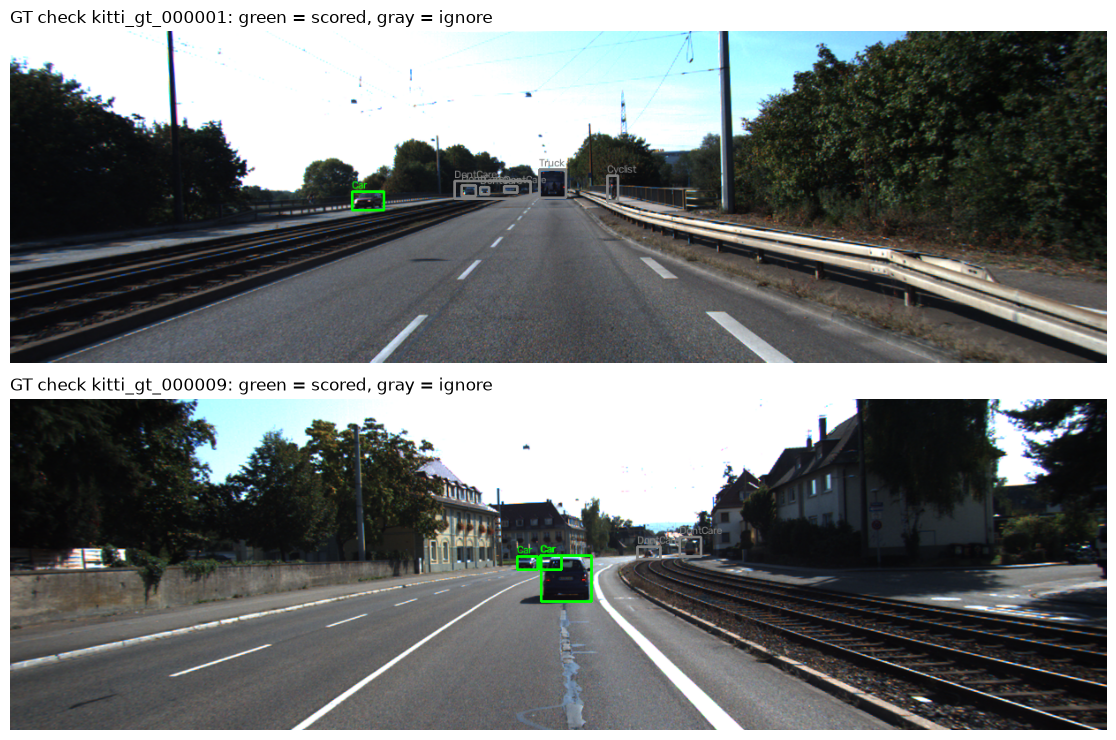

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5))
for ax, f in zip(axes, sorted((R / "figs").glob("kitti_gt_*.png"))[1:3]):
    ax.imshow(cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)); ax.set_title(f"GT check {f.stem}: green = scored, gray = ignore", loc="left"); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Reproducibility — setup, settings and commands

In [5]:
import platform, torchvision, ultralytics, pycocotools
print("GPU      :", torch.cuda.get_device_name(), f"({torch.cuda.get_device_properties(0).total_memory/2**30:.0f} GB)")
print("Driver   :", subprocess.run(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip())
print("CPU      :", platform.processor() or platform.machine(), "| OS:", platform.platform())
print("Python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| ultralytics", ultralytics.__version__, "| CUDA", torch.version.cuda, "| conda env: cnn")

GPU      : NVIDIA GeForce RTX 5080 (15 GB)
Driver   : 595.99.02
CPU      : x86_64 | OS: Linux-6.8.0-138-generic-x86_64-with-glibc2.35
Python 3.11.17 | torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | ultralytics 8.4.194 | CUDA 12.8 | conda env: cnn


In [6]:
rows = []
for (n, ds), r in res.items():
    m = r["model"]
    rows.append({"Model": n, "Dataset": ds, "Images": r["dataset"]["num_images"], "Input resize": m["resize"],
                 "conf": m["conf"], "NMS": ("IoU %.1f" % m.get("nms_iou", m.get("iou", 0.7))) if (m.get("nms") or "nms_iou" in m) else "none (NMS-free)",
                 "max det": m["max_det"], "precision": m["precision"], "command": r["command"]})
pd.DataFrame(rows).set_index(["Model", "Dataset"])

Images                       Input resize     conf  \
Model           Dataset                                                       
YOLO26-L        coco       5000           letterbox, long side 640  1.0e-03   
                kitti      1000           letterbox, long side 640  1.0e-03   
YOLO26-L +NMS   coco       5000           letterbox, long side 640  1.0e-03   
                kitti      1000           letterbox, long side 640  1.0e-03   
RT-DETR-L       coco       5000           letterbox, long side 640  1.0e-03   
                kitti      1000           letterbox, long side 640  1.0e-03   
Faster R-CNN v2 coco       5000  short side 800, long side <= 1333  1.0e-03   
                kitti      1000  short side 800, long side <= 1333  1.0e-03   

                                     NMS  max det precision  \
Model           Dataset                                       
YOLO26-L        coco     none (NMS-free)      300      fp32   
                kitti    none (NMS-free)      300      fp32   
YOLO26-L +NMS   coco             IoU 0.7      300      fp32   
                kitti            IoU 0.7      300      fp32   
RT-DETR-L       coco     none (NMS-free)      300      fp32   
                kitti    none (NMS-free)      300      fp32   
Faster R-CNN v2 coco             IoU 0.5      100      fp32   
                kitti            IoU 0.5      100      fp32   

                                                                   command  
Model           Dataset                                                     
YOLO26-L        coco         python eval.py --model yolo26l --dataset coco  
                kitti       python eval.py --model yolo26l --dataset kitti  
YOLO26-L +NMS   coco     python eval.py --model yolo26l-nms --dataset coco  
                kitti    python eval.py --model yolo26l-nms --dataset k...  
RT-DETR-L       coco        python eval.py --model rtdetr-l --dataset coco  
                kitti      python eval.py --model rtdetr-l --dataset kitti  
Faster R-CNN v2 coco           python eval.py --model frcnn --dataset coco  
                kitti         python eval.py --model frcnn --dataset kitti

Common protocol: batch 1, fp32, confidence threshold 0.001 (standard for mAP), pycocotools `COCOeval` (maxDets 100). Latency = end-to-end `predict()` (preprocess + forward + postprocess/NMS) with `cuda.synchronize()`, first 20 images excluded as warm-up. Full log: `logs/commands.md`, env: `requirements-lock.txt`, `logs/hardware.txt`, per-run logs `logs/eval_*.log`.

## 4. Evidence: live inference with each detector (same `detectors/` interface used by `eval.py`)

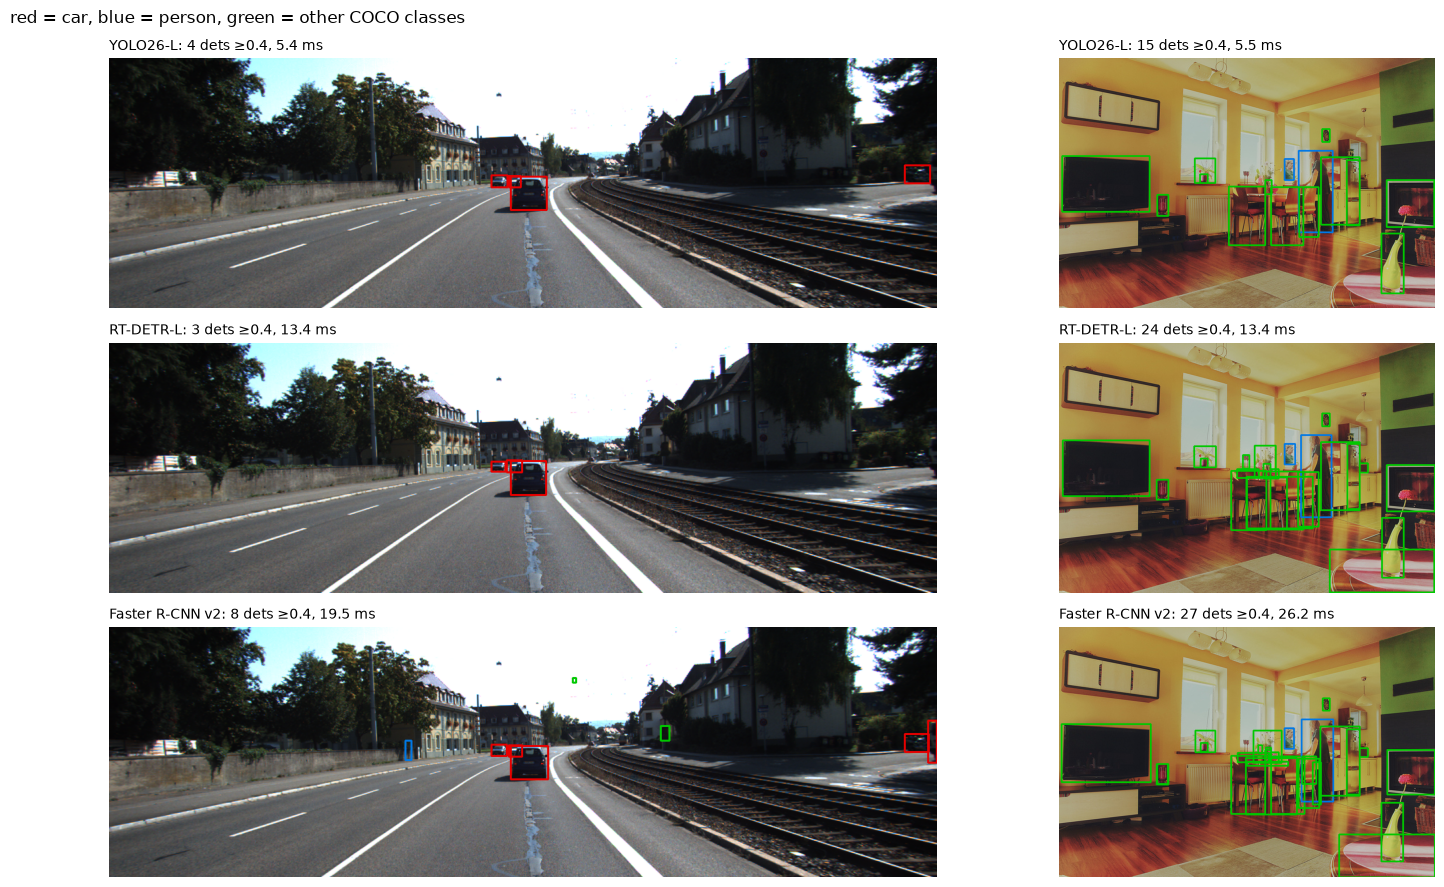

In [7]:
import sys; sys.path.insert(0, ".")
from detectors import load_detector
img_k = cv2.imread(f"{KITTI_IMG}/000009.png")
img_c = cv2.imread("data/coco/val2017/000000000139.jpg")
fig, axes = plt.subplots(3, 2, figsize=(15, 9), gridspec_kw={"width_ratios": [2.2, 1]})
for row, (name, key) in zip(axes, [("YOLO26-L", "yolo26l"), ("RT-DETR-L", "rtdetr-l"), ("Faster R-CNN v2", "frcnn")]):
    det = load_detector(key)
    for ax, img in zip(row, (img_k, img_c)):
        for _ in range(3): det.predict(img)  # warm-up
        torch.cuda.synchronize(); import time; t0 = time.perf_counter(); d = det.predict(img); torch.cuda.synchronize()
        ms = (time.perf_counter() - t0) * 1000
        vis = img.copy(); keep = d.scores >= 0.4
        for (x1, y1, x2, y2), c in zip(d.boxes[keep].astype(int), d.cat_ids[keep]):
            cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 230) if c == 3 else (230, 120, 0) if c == 1 else (0, 200, 0), 2)
        ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.axis("off")
        ax.set_title(f"{name}: {keep.sum()} dets ≥0.4, {ms:.1f} ms", loc="left", fontsize=10)
    del det; torch.cuda.empty_cache()
plt.suptitle("red = car, blue = person, green = other COCO classes", x=0.01, ha="left"); plt.tight_layout(); plt.show()

## 5. Quantitative results — all 12 COCO metrics (×100)

In [8]:
PUBLISHED = {"YOLO26-L": "≈55 (Ultralytics docs)", "YOLO26-L +NMS": "≈55 (Ultralytics docs)", "RT-DETR-L": "53.0", "Faster R-CNN v2": "46.7"}
for ds, title in [("coco", "COCO val2017 (80 classes, 5,000 images)"), ("kitti", "KITTI subset (car + person, 1,000 images)")]:
    display(Markdown(f"**{title}**"))
    t = pd.DataFrame({n: {k: 100 * v for k, v in res[(n, ds)]["metrics"].items()} for n, _ in MODELS}).T[STATS]
    if ds == "coco": t["published AP"] = [PUBLISHED[n] for n in t.index]
    display(t)

**COCO val2017 (80 classes, 5,000 images)**

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR1,AR10,AR100,AR_small,AR_medium,AR_large,published AP
YOLO26-L,53.8,70.7,58.8,37.2,58.0,69.5,39.8,67.0,73.1,57.3,78.0,86.5,≈55 (Ultralytics docs)
YOLO26-L +NMS,54.0,71.0,58.9,35.9,58.3,69.8,39.0,64.8,69.6,52.2,74.8,83.1,≈55 (Ultralytics docs)
RT-DETR-L,52.8,71.3,57.2,34.4,57.4,70.8,38.8,65.2,71.7,54.6,75.8,89.0,53.0
Faster R-CNN v2,46.9,67.9,51.3,31.0,50.8,60.3,37.0,59.5,63.0,47.3,66.5,77.4,46.7


**KITTI subset (car + person, 1,000 images)**

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR1,AR10,AR100,AR_small,AR_medium,AR_large
YOLO26-L,39.6,72.9,38.4,23.6,37.9,55.5,17.7,46.1,51.3,41.1,51.0,62.3
YOLO26-L +NMS,39.8,72.7,38.9,23.8,37.8,55.6,18.0,46.0,49.1,38.3,48.2,61.6
RT-DETR-L,40.1,72.5,38.6,25.1,37.3,57.2,17.7,45.7,50.4,43.0,48.3,62.7
Faster R-CNN v2,40.4,74.6,38.3,25.7,38.0,55.4,18.2,47.8,51.5,46.5,49.1,61.9


**Sanity check:** COCO mAP reproduces the published numbers (RT-DETR-L 52.8 vs 53.0, Faster R-CNN 46.9 vs 46.7). YOLO26-L is ~1 pt below the docs figure because the docs use `yolo val` (rectangular batching, different padding); we use per-image `predict()`, identical for all models.

In [9]:
pc = pd.DataFrame({(n, ds): {k: 100 * v for k, v in res[(n, ds)]["per_class_AP"].items() if k in ("car", "person")}
                   for n, _ in MODELS for ds in ("coco", "kitti")}).T
pc.index.names = ["Model", "Dataset"]; pc.unstack("Dataset")

person         car      
Dataset           coco kitti  coco kitti
Model                                   
Faster R-CNN v2   59.6  31.3  49.9  49.6
RT-DETR-L         61.7  29.0  50.1  51.3
YOLO26-L          65.0  29.6  53.7  49.5
YOLO26-L +NMS     65.2  30.1  53.6  49.6

Per-class AP for the two shared classes (COCO per-class AP for all 80 classes is stored in `results/*_coco.json`).

## 6. Analysis 1 — Cross-dataset generalization (COCO → KITTI)

COCO-80 mAP is not comparable to a 2-class KITTI mAP, so we **re-score each model's COCO predictions on car + person only ("COCO-2")**. The COCO → KITTI difference is then a like-for-like domain-shift measurement.

In [10]:
coco2 = {}
rows = []
for n, tag in MODELS:
    E = run_eval(coco_gt, res[(n, "coco")]["pred_file"], [1, 3]); coco2[n] = E
    k = res[(n, "kitti")]["metrics"]
    for s, (ci, kk) in {"AP": (0, "AP"), "AP50": (1, "AP50"), "AP75": (2, "AP75"), "AP_small": (3, "AP_small"),
                        "AP_medium": (4, "AP_medium"), "AP_large": (5, "AP_large"), "AR100": (8, "AR100")}.items():
        rows.append({"Model": n, "metric": s, "COCO-2": 100 * E.stats[ci], "KITTI": 100 * k[kk], "Δ": 100 * (k[kk] - E.stats[ci])})
x = pd.DataFrame(rows).pivot(index="Model", columns="metric", values=["COCO-2", "KITTI", "Δ"])
x.loc[[n for n, _ in MODELS], [(a, b) for a in ("COCO-2", "KITTI", "Δ") for b in ("AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR100")]]

COCO-2                                               KITTI  \
metric              AP  AP50  AP75 AP_small AP_medium AP_large AR100    AP   
Model                                                                        
YOLO26-L          59.4  81.1  64.9     43.2      71.3     82.7  72.8  39.6   
YOLO26-L +NMS     59.4  81.3  64.9     43.5      71.8     81.7  70.4  39.8   
RT-DETR-L         55.9  80.0  60.1     39.5      67.7     81.7  69.0  40.1   
Faster R-CNN v2   54.8  81.3  59.9     41.6      64.6     72.8  65.8  40.4   

                             ...                              Δ             \
metric           AP50  AP75  ... AP_medium AP_large AR100    AP AP50  AP75   
Model                        ...                                             
YOLO26-L         72.9  38.4  ...      37.9     55.5  51.3 -19.8 -8.2 -26.5   
YOLO26-L +NMS    72.7  38.9  ...      37.8     55.6  49.1 -19.6 -8.6 -26.0   
RT-DETR-L        72.5  38.6  ...      37.3     57.2  50.4 -15.8 -7.6 -21.6   
Faster R-CNN v2  74.6  38.3  ...      38.0     55.4  51.5 -14.4 -6.7 -21.6   

                                                   
metric          AP_small AP_medium AP_large AR100  
Model                                              
YOLO26-L           -19.6     -33.3    -27.2 -21.5  
YOLO26-L +NMS      -19.6     -34.0    -26.0 -21.4  
RT-DETR-L          -14.5     -30.4    -24.6 -18.6  
Faster R-CNN v2    -15.9     -26.5    -17.4 -14.4  

[4 rows x 21 columns]

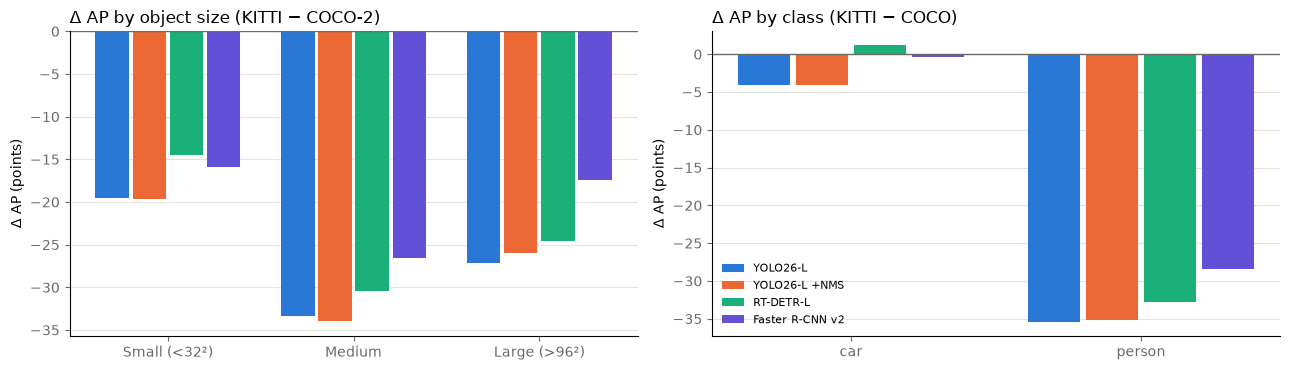

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sizes = [("Small (<32²)", 3, "AP_small"), ("Medium", 4, "AP_medium"), ("Large (>96²)", 5, "AP_large")]
w = 0.2
for i, (n, _) in enumerate(MODELS):
    xs = np.arange(3) + (i - 1.5) * w
    axes[0].bar(xs, [100 * (res[(n, "kitti")]["metrics"][kk] - coco2[n].stats[ci]) for _, ci, kk in sizes], w * 0.9, color=COLORS[n], label=n)
    pcs = [100 * (res[(n, "kitti")]["per_class_AP"][c] - res[(n, "coco")]["per_class_AP"][c]) for c in ("car", "person")]
    axes[1].bar(np.arange(2) + (i - 1.5) * w, pcs, w * 0.9, color=COLORS[n], label=n)
axes[0].set_xticks(range(3), [s for s, _, _ in sizes]); axes[0].set_title("Δ AP by object size (KITTI − COCO-2)", loc="left")
axes[1].set_xticks(range(2), ["car", "person"]); axes[1].set_title("Δ AP by class (KITTI − COCO)", loc="left")
for ax in axes: style(ax); ax.axhline(0, color="#6b6a63", lw=1); ax.set_ylabel("Δ AP (points)")
axes[1].legend(frameon=False, fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

**Which classes degrade most?** *Person.* Car AP is essentially unchanged COCO → KITTI (≈50 → ≈50), but person AP roughly **halves** for every model (≈60–65 → ≈29–31). This is **not** a size effect: median person height is about the same on both datasets (KITTI 87 px vs COCO 83 px; KITTI cars are actually *larger* than COCO cars, 47 vs 26 px). The person drop comes from what §7 shows: occlusion, pedestrians in groups, and the street-level vehicle viewpoint.

**Which scales degrade most?** *Medium* objects drop the most (−27 to −34 AP), then large, then small. Small objects were already hard on COCO, so they have less to lose; medium-sized KITTI objects are mostly occluded parked cars and pedestrians (§7).

**Ranking flips:** YOLO26-L leads on COCO but drops the most (−19.8 AP on COCO-2 → KITTI); Faster R-CNN drops least (−14.4) and is marginally best on KITTI. All four are within 1 AP on KITTI.

## 7. Deep dive — why does KITTI hurt? Difficulty, occlusion, object height, PR curves

KITTI defines **Easy / Moderate / Hard** by box height, occlusion and truncation. We re-run pycocotools with GT outside each level marked ignored (area set out of range → standard IoU-ignore), so detections on those objects are neither rewarded nor penalized.

| Level | min height | max occlusion | max truncation |
|---|---|---|---|
| Easy | 40 px | 0 (fully visible) | 0.15 |
| Moderate | 25 px | 1 (partly occluded) | 0.30 |
| Hard | 25 px | 2 (largely occluded) | 0.50 |

In [12]:
def kitti_subset_gt(keep):
    d = copy.deepcopy(kd)
    for a in d["annotations"]:
        if not a["iscrowd"] and not keep(a):
            a["area"] = 1e11  # outside areaRng 'all' -> ignored with normal IoU matching
    c = COCO(); c.dataset = d; quiet(c.createIndex); return c

LEVELS = {
    "Easy":     lambda a: a["bbox"][3] >= 40 and a["occluded"] <= 0 and a["truncated"] <= 0.15,
    "Moderate": lambda a: a["bbox"][3] >= 25 and a["occluded"] <= 1 and a["truncated"] <= 0.30,
    "Hard":     lambda a: a["bbox"][3] >= 25 and a["occluded"] <= 2 and a["truncated"] <= 0.50,
    "occ=0 visible": lambda a: a["occluded"] == 0,
    "occ=1 partly":  lambda a: a["occluded"] == 1,
    "occ=2 largely": lambda a: a["occluded"] == 2,
}
gts = {k: kitti_subset_gt(f) for k, f in LEVELS.items()}
n_gt = {k: sum(1 for a in kd["annotations"] if not a["iscrowd"] and f(a)) for k, f in LEVELS.items()}
rows = []
for n, _ in MODELS:
    pf = res[(n, "kitti")]["pred_file"]
    row = {"Model": n}
    for k, g in gts.items():
        E = run_eval(g, pf); row[(k, "AP")] = 100 * E.stats[0]; row[(k, "AP50")] = 100 * E.stats[1]
    rows.append(row)
diff = pd.DataFrame(rows).set_index("Model"); diff.columns = pd.MultiIndex.from_tuples(diff.columns)
print("GT boxes per level:", n_gt); diff

GT boxes per level: {'Easy': 1060, 'Moderate': 2557, 'Hard': 3469, 'occ=0 visible': 2148, 'occ=1 partly': 1241, 'occ=2 largely': 935}


Easy       Moderate        Hard       occ=0 visible        \
                   AP  AP50       AP  AP50    AP  AP50            AP  AP50   
Model                                                                        
YOLO26-L         54.3  91.3     47.4  84.3  40.0  74.1          51.1  86.7   
YOLO26-L +NMS    55.3  91.5     47.7  84.0  40.3  74.0          51.7  86.6   
RT-DETR-L        55.0  90.3     47.8  83.2  40.3  73.1          51.8  85.6   
Faster R-CNN v2  54.9  91.1     48.2  84.8  40.6  75.1          51.9  87.3   

                occ=1 partly       occ=2 largely        
                          AP  AP50            AP  AP50  
Model                                                   
YOLO26-L                22.9  53.3           5.4  21.2  
YOLO26-L +NMS           23.1  53.3           5.4  21.5  
RT-DETR-L               24.9  55.0           6.3  24.4  
Faster R-CNN v2         23.4  54.0           5.7  23.6

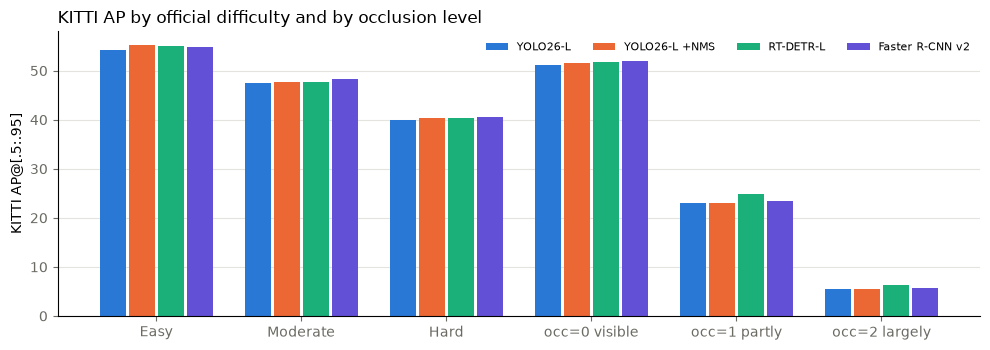

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.6))
keys = list(LEVELS); w = 0.2
for i, (n, _) in enumerate(MODELS):
    ax.bar(np.arange(len(keys)) + (i - 1.5) * w, [diff.loc[n, (k, "AP")] for k in keys], w * 0.9, color=COLORS[n], label=n)
ax.set_xticks(range(len(keys)), keys); ax.set_ylabel("KITTI AP@[.5:.95]"); style(ax)
ax.set_title("KITTI AP by official difficulty and by occlusion level", loc="left"); ax.legend(frameon=False, fontsize=8, ncol=4)
plt.tight_layout(); plt.show()

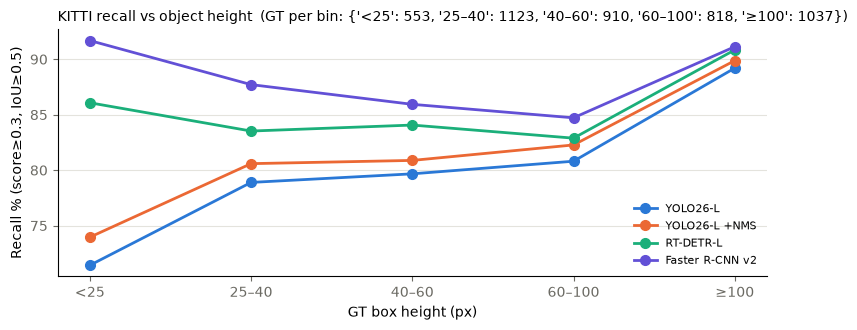

In [14]:
# recall at score >= 0.3, IoU >= 0.5, bucketed by GT box height
def iou_xywh(a, b):
    iw = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0])); ih = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    i = iw * ih; return i / (a[2] * a[3] + b[2] * b[3] - i + 1e-9)
gt_by = {}
for a in kd["annotations"]:
    if not a["iscrowd"]: gt_by.setdefault(a["image_id"], []).append(a)
BINS = [0, 25, 40, 60, 100, 1e9]; LBL = ["<25", "25–40", "40–60", "60–100", "≥100"]
rec = {}
for n, _ in MODELS:
    pr = {}
    for p in json.loads(Path(res[(n, "kitti")]["pred_file"]).read_text()):
        if p["score"] >= 0.3: pr.setdefault(p["image_id"], []).append(p)
    hit = np.zeros(len(LBL)); tot = np.zeros(len(LBL))
    for img_id, gs in gt_by.items():
        for g in gs:
            b = np.digitize(g["bbox"][3], BINS) - 1; tot[b] += 1
            hit[b] += any(p["category_id"] == g["category_id"] and iou_xywh(p["bbox"], g["bbox"]) >= 0.5 for p in pr.get(img_id, []))
    rec[n] = 100 * hit / tot
fig, ax = plt.subplots(figsize=(8, 3.4))
for n, _ in MODELS: ax.plot(LBL, rec[n], marker="o", lw=2, ms=7, color=COLORS[n], label=n)
ax.set_xlabel("GT box height (px)"); ax.set_ylabel("Recall % (score≥0.3, IoU≥0.5)"); style(ax)
ax.set_title(f"KITTI recall vs object height  (GT per bin: {dict(zip(LBL, tot.astype(int).tolist()))})", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

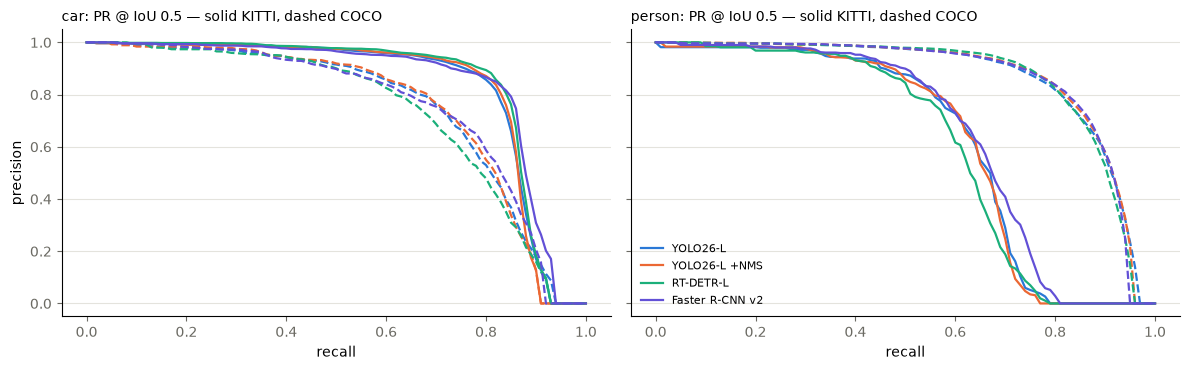

In [15]:
# Precision-recall at IoU 0.5, COCO-2 (dashed) vs KITTI (solid), per class
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
rc = np.linspace(0, 1, 101)
for n, _ in MODELS:
    Ek = run_eval(kitti_gt, res[(n, "kitti")]["pred_file"])
    for ax, cat in zip(axes, (3, 1)):
        for E, ls in ((coco2[n], "--"), (Ek, "-")):
            k = E.params.catIds.index(cat); p = E.eval["precision"][0, :, k, 0, -1]
            ax.plot(rc[p > -1], p[p > -1], ls, color=COLORS[n], lw=1.6, label=f"{n}" if ls == "-" else None)
for ax, t in zip(axes, ("car", "person")):
    ax.set_title(f"{t}: PR @ IoU 0.5 — solid KITTI, dashed COCO", loc="left", fontsize=10); ax.set_xlabel("recall"); style(ax)
axes[0].set_ylabel("precision"); axes[1].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

**Take-aways**
- AP falls steeply from *Easy* to *Hard* and from fully visible to largely occluded objects: **occlusion is the dominant failure factor** on KITTI, not class confusion.
- Recall vs height splits by input resolution: YOLO26-L drops to ~72% for boxes < 25 px, RT-DETR-L to ~86%, while Faster R-CNN (≈2× the input pixels) keeps ~92%. For ≥ 100 px all models converge at ~90%.
- Car PR curves on KITTI stay close to COCO; person curves lose both precision and maximum recall.

### 7b. Controlled test: is the KITTI gap just input resolution?

KITTI frames are 1242×375. Ultralytics letterboxes to 640 → **640×193 (0.52×)**; torchvision Faster R-CNN resizes to **1333×403 (1.07×)**. We re-ran YOLO26-L and RT-DETR-L at `--imgsz 1280` (1280×386).

In [16]:
rows = []
for name, tag, eff in [("YOLO26-L", "yolo26l_kitti", "640×193"), ("YOLO26-L", "yolo26l_1280_kitti", "1280×386"),
                       ("RT-DETR-L", "rtdetr-l_kitti", "640×193"), ("RT-DETR-L", "rtdetr-l_1280_kitti", "1280×386"),
                       ("Faster R-CNN v2", "frcnn-r50-fpn-v2_kitti", "1333×403")]:
    r = load(tag)
    if r: rows.append({"Model": name, "effective input": eff, **{k: 100 * r["metrics"][k] for k in ("AP", "AP50", "AP_small", "AP_medium", "AP_large")},
                       "car": 100 * r["per_class_AP"]["car"], "person": 100 * r["per_class_AP"]["person"],
                       "ms": r["speed"]["mean_ms"], "mem MB": r["gpu_peak_mem_MB"]})
pd.DataFrame(rows).set_index(["Model", "effective input"])

AP  AP50  AP_small  AP_medium  AP_large  \
Model           effective input                                              
YOLO26-L        640×193          39.6  72.9      23.6       37.9      55.5   
                1280×386         39.9  73.9      27.5       37.4      54.6   
RT-DETR-L       640×193          40.1  72.5      25.1       37.3      57.2   
                1280×386         41.0  69.4      28.0       39.6      58.4   
Faster R-CNN v2 1333×403         40.4  74.6      25.7       38.0      55.4   

                                  car  person    ms  mem MB  
Model           effective input                              
YOLO26-L        640×193          49.5    29.6   5.5   162.6  
                1280×386         50.7    29.1   7.0   247.5  
RT-DETR-L       640×193          51.3    29.0  13.6   238.6  
                1280×386         51.1    30.9  25.4   466.0  
Faster R-CNN v2 1333×403         49.6    31.3  19.1   441.1

Doubling resolution recovers **+3–4 AP on small objects** for both Ultralytics models, but overall KITTI AP moves < 1 pt and **person AP does not improve**. Resolution explains part of the small-object gap; the person drop is a genuine domain shift (viewpoint, occlusion, crowding). Cost: RT-DETR latency 13.6 → 25.4 ms, YOLO26 5.5 → 7.0 ms.

## 8. Analysis 2 — Speed–accuracy tradeoff (latency, FPS, memory, params)

In [17]:
rows = []
for n, _ in MODELS:
    c, k = res[(n, "coco")], res[(n, "kitti")]
    rows.append({"Model": n, "Params (M)": c["params_M"], "COCO AP": 100 * c["metrics"]["AP"], "KITTI AP": 100 * k["metrics"]["AP"],
                 "COCO ms (mean)": c["speed"]["mean_ms"], "COCO ms (median)": c["speed"]["median_ms"], "COCO FPS": c["speed"]["fps"],
                 "KITTI ms": k["speed"]["mean_ms"], "KITTI FPS": k["speed"]["fps"],
                 "peak mem COCO MB": c["gpu_peak_mem_MB"], "peak mem KITTI MB": k["gpu_peak_mem_MB"], "timed imgs": c["speed"]["timed_images"]})
pd.DataFrame(rows).set_index("Model")

,Params (M),COCO AP,KITTI AP,COCO ms (mean),COCO ms (median),COCO FPS,KITTI ms,KITTI FPS,peak mem COCO MB,peak mem KITTI MB,timed imgs
Model,,,,,,,,,,,
YOLO26-L,26.3,53.8,39.6,5.6,5.5,178.2,5.5,181.8,221.1,162.6,4980
YOLO26-L +NMS,26.3,54.0,39.8,5.7,5.5,176.6,5.4,184.9,221.1,162.6,4980
RT-DETR-L,33.0,52.8,40.1,13.6,13.5,73.6,13.6,73.4,238.6,238.6,4980
Faster R-CNN v2,43.7,46.9,40.4,24.5,24.5,40.9,19.1,52.5,671.1,441.1,4980


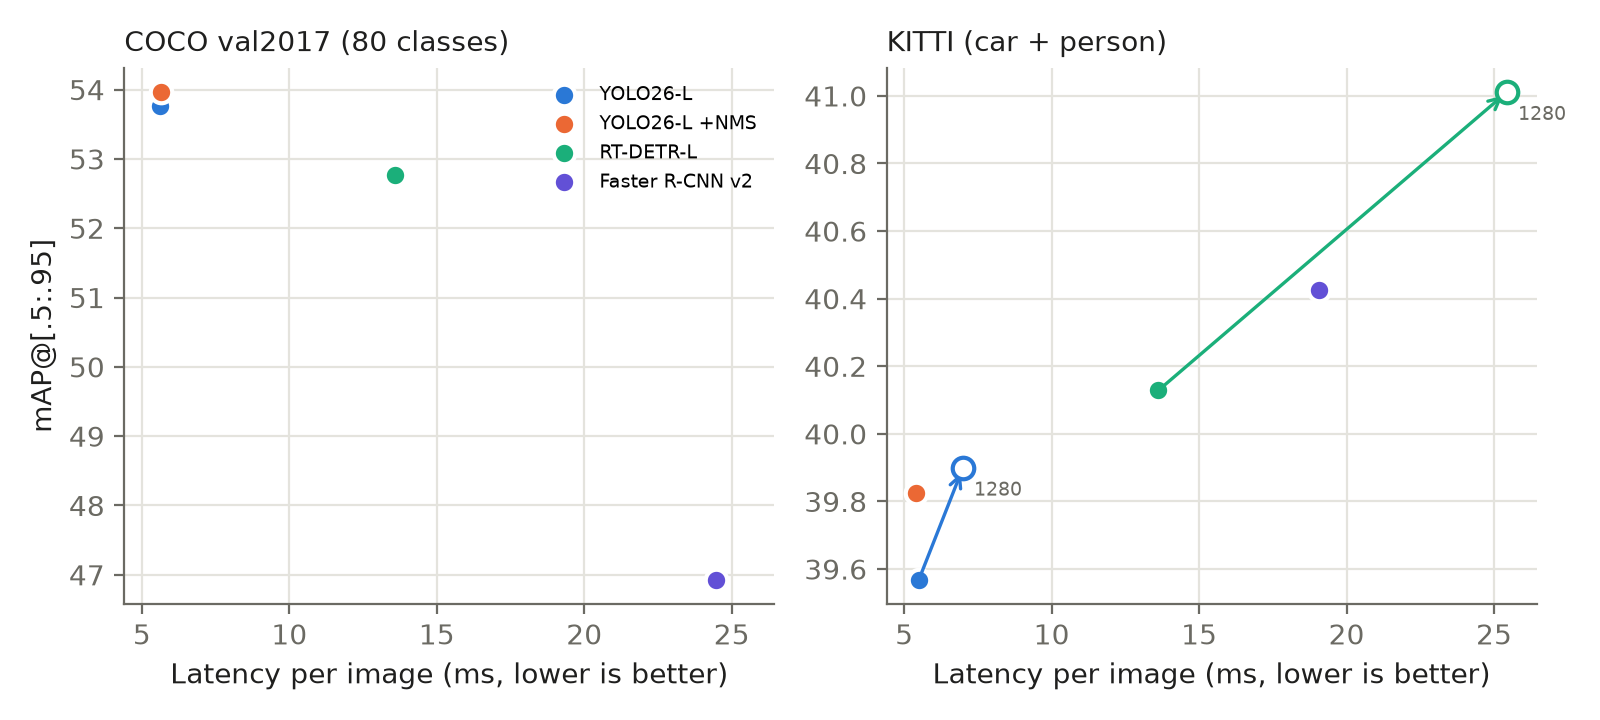

In [18]:
display(Image(filename=str(R / "figs" / "speed_vs_ap.png"), width=900))

- **YOLO26-L dominates on COCO**: highest AP *and* lowest latency (5.6 ms, ~178 FPS), 4.4× faster than Faster R-CNN with +7 AP, and 3× less GPU memory.
- **RT-DETR-L** sits in the middle (13.6 ms, 52.8 AP); its transformer encoder/decoder costs ~2.4× YOLO26's latency at the same input size.
- **Faster R-CNN** is slowest (24.5 ms on COCO, 19.1 ms on KITTI — fewer pixels per image after resize) and uses the most memory (671 MB), partly because it processes ~2× more pixels.
- On KITTI the accuracy spread collapses to ~1 AP, so **YOLO26-L is the clear speed–accuracy winner for the driving domain** (3.5× faster than Faster R-CNN for −0.8 AP). Spending latency on resolution (1280) buys at most +0.9 AP.

## 9. Analysis 3 — Architecture: NMS-free vs NMS, queries vs anchors

YOLO26 ships both heads, which gives a controlled NMS experiment on identical weights/backbone. We also count **near-duplicate detections** (same class, IoU > 0.7, both score ≥ 0.3) — the thing NMS exists to remove.

In [19]:
def dup_stats(pred_file, thr=0.3):
    by = {}
    for p in json.loads(Path(pred_file).read_text()):
        if p["score"] >= thr: by.setdefault(p["image_id"], []).append(p)
    n_det, n_dup = 0, 0
    for ps in by.values():
        n_det += len(ps)
        for i in range(len(ps)):
            for j in range(i + 1, len(ps)):
                if ps[i]["category_id"] == ps[j]["category_id"] and iou_xywh(ps[i]["bbox"], ps[j]["bbox"]) > 0.7: n_dup += 1
    return n_det / max(len(by), 1), n_dup
rows = []
for n, _ in MODELS:
    for ds in ("coco", "kitti"):
        r = res[(n, ds)]; dets, dups = dup_stats(r["pred_file"])
        rows.append({"Model": n, "Dataset": ds, "post-proc": "NMS" if n in ("YOLO26-L +NMS", "Faster R-CNN v2") else "NMS-free",
                     "AP": 100 * r["metrics"]["AP"], "AP50": 100 * r["metrics"]["AP50"], "AP75": 100 * r["metrics"]["AP75"],
                     "AR1": 100 * r["metrics"]["AR1"], "AR100": 100 * r["metrics"]["AR100"], "ms": r["speed"]["mean_ms"],
                     "dets/img (≥0.3)": dets, "dup pairs IoU>0.7": dups})
pd.DataFrame(rows).set_index(["Model", "Dataset"])

post-proc    AP  AP50  AP75   AR1  AR100    ms  \
Model           Dataset                                                  
YOLO26-L        coco     NMS-free  53.8  70.7  58.8  39.8   73.1   5.6   
                kitti    NMS-free  39.6  72.9  38.4  17.7   51.3   5.5   
YOLO26-L +NMS   coco          NMS  54.0  71.0  58.9  39.0   69.6   5.7   
                kitti         NMS  39.8  72.7  38.9  18.0   49.1   5.4   
RT-DETR-L       coco     NMS-free  52.8  71.3  57.2  38.8   71.7  13.6   
                kitti    NMS-free  40.1  72.5  38.6  17.7   50.4  13.6   
Faster R-CNN v2 coco          NMS  46.9  67.9  51.3  37.0   63.0  24.5   
                kitti         NMS  40.4  74.6  38.3  18.2   51.5  19.1   

                         dets/img (≥0.3)  dup pairs IoU>0.7  
Model           Dataset                                      
YOLO26-L        coco                 5.9                554  
                kitti                5.4                 75  
YOLO26-L +NMS   coco                 6.2                 25  
                kitti                5.7                  0  
RT-DETR-L       coco                10.4               1813  
                kitti                7.9                138  
Faster R-CNN v2 coco                13.7                  0  
                kitti               11.2                  0

- **YOLO26 NMS-free vs +NMS**: same weights, ±0.2 AP and identical latency, so NMS can be removed without accuracy loss (and with it a non-differentiable, hard-to-export, data-dependent step). The NMS-free head has **higher AR100** (73.1 vs 69.6 on COCO), the NMS head slightly higher AP50.
- **NMS-free ≠ duplicate-free.** At score ≥ 0.3 the NMS-free models still emit near-duplicates: YOLO26 one-to-one 554 pairs on COCO (≈2% of detections) and **RT-DETR 1,813 (≈3.5%)**, vs 25 / 0 for the NMS models. One-to-one assignment (YOLO26) and Hungarian matching (RT-DETR) only *train* the model to suppress duplicates; nothing enforces it at inference. AP barely suffers because the duplicate is usually the lower-scoring box and is counted as one late FP.
- **RT-DETR**: inference is top-k over 300 decoder queries. Its strength shows on large objects (best AP_large on both datasets), consistent with global self-attention in the encoder.
- **Faster R-CNN**: anchor-based RPN proposals + RoI head + NMS. Weakest on COCO but most robust to the domain shift (smallest drop) — helped by its higher input resolution and multi-scale RoI features.

## 10. Failure analysis (YOLO26-L on KITTI)

Images with the most errors at score ≥ 0.3, IoU ≥ 0.5. **Green** = GT hit, **yellow** = missed GT, **red** = prediction, **gray** = ignore region. DontCare overlap is measured as intersection-over-detection, like pycocotools.


- `fail_1_006589.png`: 18 GT, 9 missed, 3 FP, brightness 90/255. Missed: Car h=45px occ=2 trunc=0.00, Car h=39px occ=2 trunc=0.00, Car h=29px occ=2 trunc=0.00, Pedestrian h=33px occ=1 trunc=0.00, Car h=78px occ=2 trunc=0.00, Car h=55px occ=2 trunc=0.00, Car h=33px occ=2 trunc=0.00, Car h=113px occ=3 trunc=0.39, Car h=59px occ=2 trunc=0.00
- `fail_2_001457.png`: 14 GT, 8 missed, 2 FP, brightness 88/255. Missed: Car h=64px occ=2 trunc=0.00, Car h=32px occ=2 trunc=0.00, Car h=80px occ=1 trunc=0.00, Car h=54px occ=2 trunc=0.00, Car h=34px occ=2 trunc=0.00, Car h=26px occ=1 trunc=0.00, Car h=14px occ=1 trunc=0.00, Car h=44px occ=2 trunc=0.00
- `fail_3_003984.png`: 10 GT, 5 missed, 5 FP, brightness 86/255. Missed: Car h=88px occ=2 trunc=0.00, Car h=72px occ=2 trunc=0.00, Car h=67px occ=2 trunc=0.00, Car h=44px occ=2 trunc=0.00, Car h=39px occ=2 trunc=0.00
- `fail_4_004290.png`: 11 GT, 6 missed, 4 FP, brightness 102/255. Missed: Car h=168px occ=0 trunc=1.00, Car h=121px occ=2 trunc=0.00, Pedestrian h=136px occ=2 trunc=0.00, Pedestrian h=104px occ=2 trunc=0.00, Pedestrian h=107px occ=2 trunc=0.00, Car h=28px occ=2 trunc=0.00
- `fail_5_005012.png`: 13 GT, 7 missed, 3 FP, brightness 90/255. Missed: Car h=71px occ=2 trunc=0.00, Car h=43px occ=2 trunc=0.00, Car h=13px occ=1 trunc=0.00, Car h=31px occ=1 trunc=0.00, Car h=25px occ=2 trunc=0.00, Car h=20px occ=1 trunc=0.00, Car h=15px occ=1 trunc=0.00
- `fail_6_006163.png`: 16 GT, 3 missed, 7 FP, brightness 90/255. Missed: Car h=173px occ=3 trunc=0.44, Car h=57px occ=2 trunc=0.00, Car h=40px occ=2 trunc=0.00


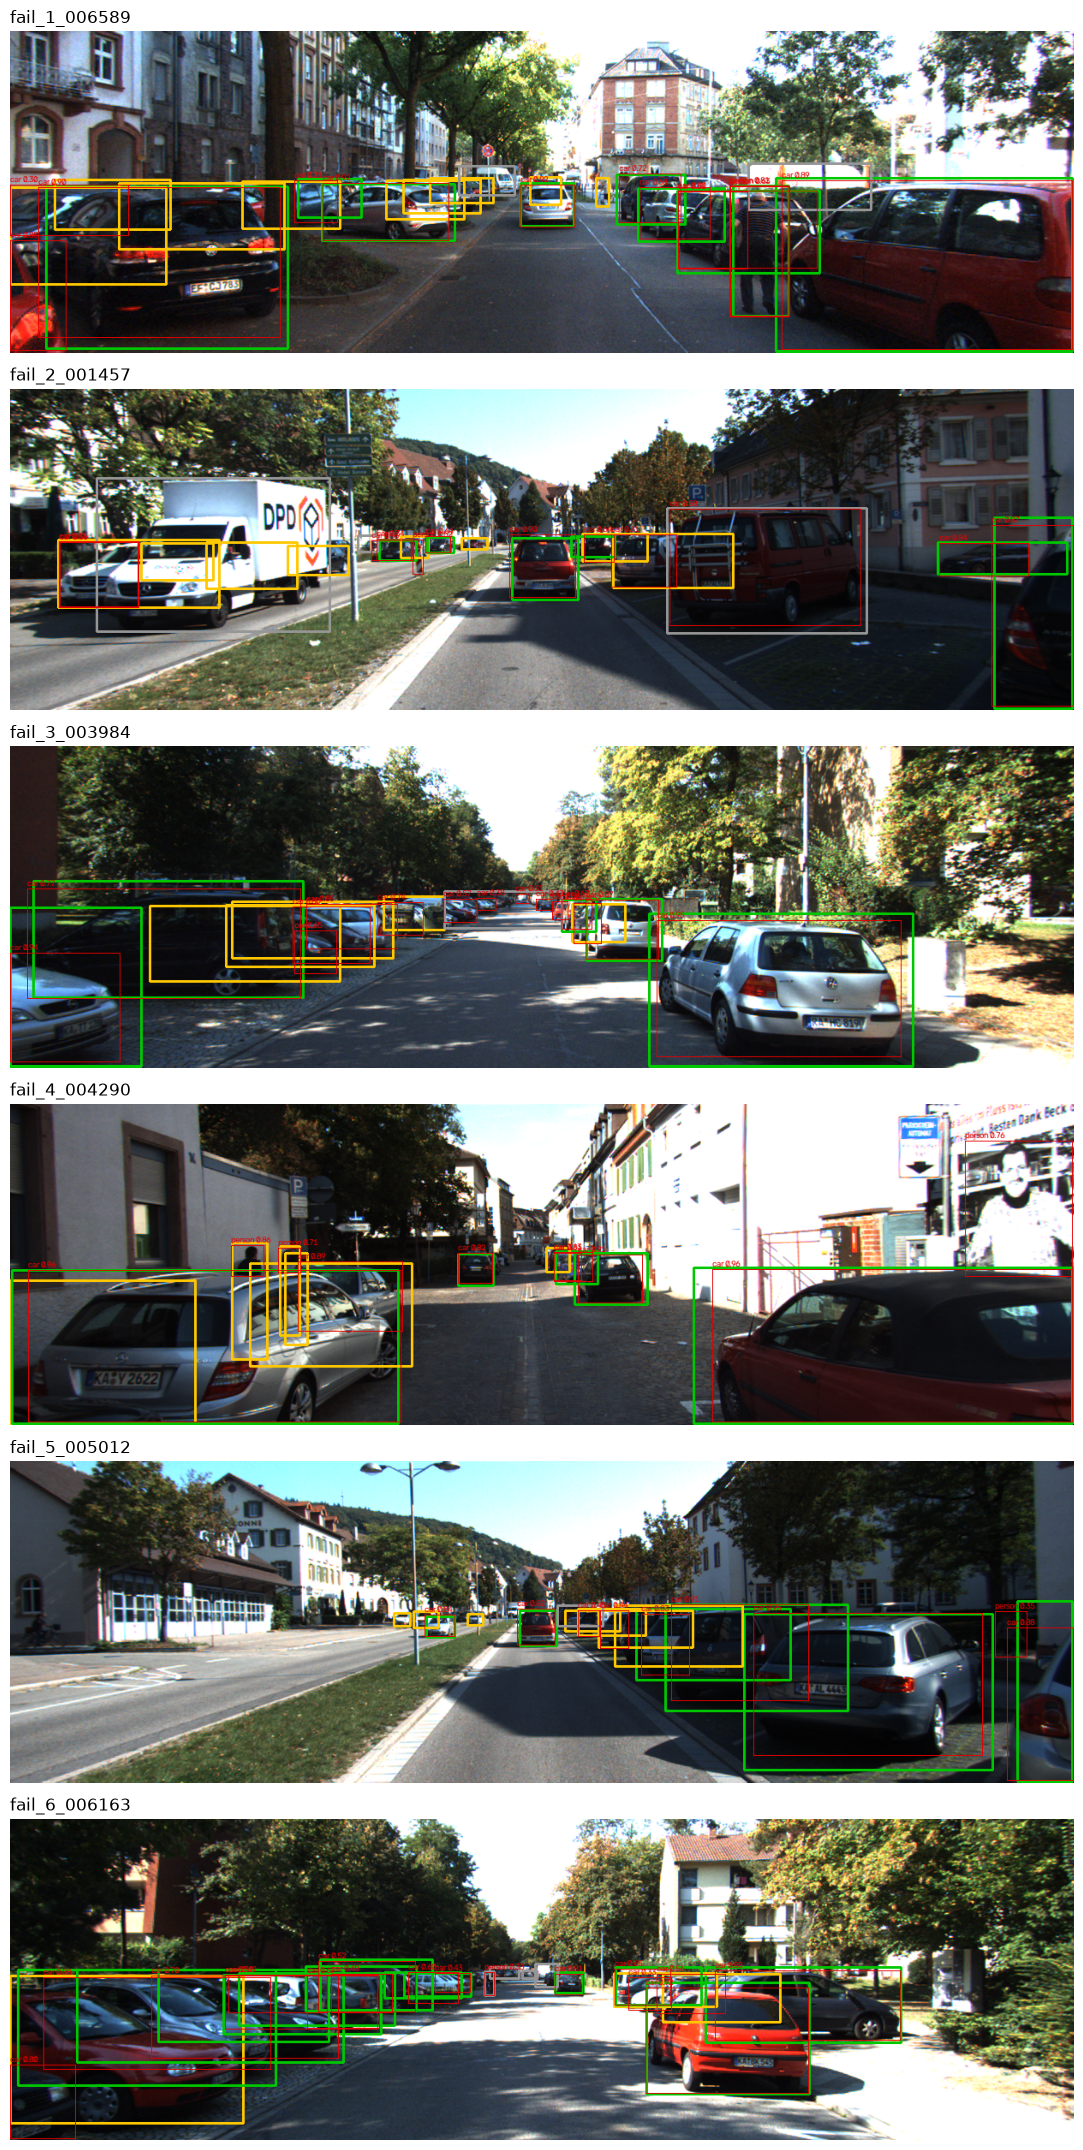

In [20]:
display(Markdown(Path(R / "failures.md").read_text().split("\n", 3)[-1]))
fails = sorted((R / "figs").glob("fail_*.png"))
fig, axes = plt.subplots(len(fails), 1, figsize=(13, 3.6 * len(fails)))
for ax, f in zip(np.atleast_1d(axes), fails):
    ax.imshow(cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)); ax.set_title(f.stem, loc="left"); ax.axis("off")
plt.tight_layout(); plt.show()

In [21]:
# what are the missed GT, across all models? (score >= 0.3, IoU >= 0.5)
rows = []
for n, _ in MODELS:
    pr = {}
    for p in json.loads(Path(res[(n, "kitti")]["pred_file"]).read_text()):
        if p["score"] >= 0.3: pr.setdefault(p["image_id"], []).append(p)
    for img_id, gs in gt_by.items():
        for g in gs:
            if not any(p["category_id"] == g["category_id"] and iou_xywh(p["bbox"], g["bbox"]) >= 0.5 for p in pr.get(img_id, [])):
                rows.append({"Model": n, "class": g["kitti_class"], "occluded": g["occluded"], "small (<40px)": g["bbox"][3] < 40,
                             "truncated>0.3": g["truncated"] > 0.3})
m = pd.DataFrame(rows)
summary = m.groupby("Model").agg(missed=("class", "size"),
                                 pct_largely_occluded=("occluded", lambda s: 100 * (s >= 2).mean()),
                                 pct_small=("small (<40px)", lambda s: 100 * s.mean()),
                                 pct_truncated=("truncated>0.3", lambda s: 100 * s.mean()),
                                 pct_pedestrian=("class", lambda s: 100 * (s == "Pedestrian").mean()))
summary.loc[[n for n, _ in MODELS]]

,missed,pct_largely_occluded,pct_small,pct_truncated,pct_pedestrian
Model,,,,,
YOLO26-L,849,58.9,46.5,10.1,22.3
YOLO26-L +NMS,786,59.2,46.1,10.8,23.8
RT-DETR-L,642,63.6,40.8,11.7,26.8
Faster R-CNN v2,529,69.8,34.8,12.9,23.8


**Failure modes**
1. **Heavily occluded parked cars** (KITTI `occluded=2`) in rows along the curb: 59–70% of all misses for every model, and AP on largely occluded objects is only 5–6 vs ~52 on fully visible ones. COCO rarely contains long rows of overlapping, side-on cars.
2. **Small distant objects** (< 40 px tall): 35–47% of misses; downscaled to ~12–20 px at 640 input. Faster R-CNN (≈2× input pixels) misses the fewest (529 total vs 849 for YOLO26-L).
3. **Pedestrians** are 22–27% of misses, even though they are only ~12% of scored GT.
4. **Apparent false positives** on parked cars in unlabeled regions — mostly absorbed by DontCare ignore regions; without them (e.g. ngdet-style evaluation) they would count as FPs and lower AP.
5. Image brightness on these failures (~86–102/255) is typical for KITTI, so illumination is **not** a primary driver in this subset.

## 11. Conclusions

- **COCO accuracy does not transfer as a ranking.** YOLO26-L > RT-DETR-L > Faster R-CNN on COCO (53.8 / 52.8 / 46.9), but on zero-shot KITTI all three are within ~1 AP (39.6–40.4), and Faster R-CNN degrades least.
- **The domain gap is class- and occlusion-specific:** cars transfer almost perfectly; person AP halves despite similar object size; AP falls from ~52 (fully visible) to ~6 (largely occluded), and occluded objects are 59–70% of misses.
- **Resolution is part of the story only for small objects:** 1280 input adds +3–4 AP_small but < 1 AP overall and nothing for persons.
- **NMS-free costs no AP, but isn't duplicate-free:** YOLO26's one-to-one head equals its NMS head (±0.2 AP) at the same latency; RT-DETR is NMS-free by design. Both still emit 2–3.5% near-duplicate boxes, which matters for downstream counting/tracking more than for mAP.
- **Best speed–accuracy for driving:** YOLO26-L (5.5 ms, ~180 FPS, 163–221 MB) — within 1 AP of the best KITTI model at 3.5× lower latency.

## 12. References

**Papers**
1. S. Ren, K. He, R. Girshick, J. Sun. *Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks.* NeurIPS 2015.
2. T.-Y. Lin et al. *Feature Pyramid Networks for Object Detection.* CVPR 2017.
3. Y. Li, S. Xie, X. Chen, P. Dollár, K. He, R. Girshick. *Benchmarking Detection Transfer Learning with Vision Transformers.* arXiv:2111.11429, 2021 (basis of torchvision's Faster R-CNN v2 recipe).
4. N. Carion et al. *End-to-End Object Detection with Transformers (DETR).* ECCV 2020.
5. Y. Zhao et al. *DETRs Beat YOLOs on Real-time Object Detection (RT-DETR).* CVPR 2024.
6. A. Wang et al. *YOLOv10: Real-Time End-to-End Object Detection* (consistent dual assignment for NMS-free YOLO). NeurIPS 2024.
7. T.-Y. Lin et al. *Microsoft COCO: Common Objects in Context.* ECCV 2014.
8. A. Geiger, P. Lenz, R. Urtasun. *Are we ready for Autonomous Driving? The KITTI Vision Benchmark Suite.* CVPR 2012.

**Repositories / documentation**
9. Ultralytics YOLO26 and RT-DETR docs and code — https://docs.ultralytics.com, https://github.com/ultralytics/ultralytics (v8.4.194)
10. torchvision detection models — https://pytorch.org/vision/stable/models.html (`fasterrcnn_resnet50_fpn_v2`, recipe: pytorch/vision PR #5763)
11. pycocotools / COCO API — https://github.com/cocodataset/cocoapi
12. Course tutorial `ngdet` — https://github.com/lkk688/DeepDataMiningLearning/blob/main/DeepDataMiningLearning/ngdet/TUTORIAL.md